# Distributed Quantum Reservoir Computing — reproduction notebook

**Paper:** Liliopoulos *et al.*, arXiv:2605.04991 (2026). Paper, claims and verdicts: [README](README.md); choices and naming: [`docs/reproduction_details.md`](docs/reproduction_details.md).

**What we found, and where the evidence is:**
1. **The paper's numbers reproduce:** against the paper baseline, the MAE reductions are of the same order as the paper's (Section 2).
2. **The gain is not quantum:** it comes from the kernel readout; a classical kernel applied to the last 4 hours, without any reservoir, does as well as the best quantum model (Section 3).
3. **The architecture holds and is easy to distribute:** it carries over to photonics with MerLin (Section 4), and its branches run in parallel with the same forecast (Section 5). This is the basis of our distributed proof of concept.

In [1]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

warnings.filterwarnings("ignore")

# Locate the paper folder (this notebook lives in papers/distributed_qrc/).
PAPER_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lib" / "runner.py").exists() and p.name == "distributed_qrc")
REPO_ROOT = PAPER_DIR.parents[1]
for path in (str(REPO_ROOT), str(PAPER_DIR.parent)):
    if path not in sys.path:
        sys.path.insert(0, path)

from runtime_lib.config import load_config
from runtime_lib.dtypes import resolve_config_dtypes

# Every scientific computation below goes through the reproduction library in lib/.
from distributed_qrc.lib.data import build_forecast_data
from distributed_qrc.lib.kernels import bloch_vectors, kernel_block
from distributed_qrc.lib.noise import IDEAL
from distributed_qrc.lib.quantum_neuron import neuron_expectations, neuron_functional

RESULTS = PAPER_DIR / "results" / "data"
COLORS = {"quantum": "tab:blue", "baseline": "tab:gray"}
ARCHS = ("srsr", "mrsr", "srmr", "mrmr")
torch.set_num_threads(4)
START = time.perf_counter()
print("paper folder:", PAPER_DIR.relative_to(REPO_ROOT), "| torch", torch.__version__, "| CPU only:", not torch.cuda.is_available())

paper folder: papers/distributed_qrc | torch 2.12.1 | CPU only: True


In [2]:
def load_paper_config() -> dict:
    # Same resolution as implementation.py for the default config.
    cfg = resolve_config_dtypes(load_config(PAPER_DIR / "configs" / "defaults.json"))
    cfg["device"] = "cpu"
    return cfg

def show(df: pd.DataFrame, floatfmt: str = "{:.4f}") -> None:
    display(df.style.format(floatfmt, subset=df.select_dtypes("float").columns).hide(axis="index"))

def read_json(name: str):
    return json.loads((RESULTS / name).read_text())

## 1. Task, data and protocol

Forecast the next hourly Greek electricity load from the last 4 hours (data and splits: README). Every hyperparameter is chosen on the evaluation split and the test split is used once; results are mean ± std over seeds 0, 1, 2.

In [3]:
cfg = load_paper_config()
data = build_forecast_data(cfg)
meta = data.metadata
rows = [{"split": s, "raw values": meta["splits"][s]["raw_values"], "windows": data.inputs[s].shape[0],
         "first day": meta["splits"][s]["first_day"], "target mean (norm.)": float(data.targets[s].mean())} for s in ("train", "eval", "test")]
show(pd.DataFrame(rows), "{:.3f}")
print("series length:", meta["length"], "| fingerprint OK:", meta["fingerprint_sha256"][:12], "| window shape:", data.inputs["train"].shape)

split,raw values,windows,first day,target mean (norm.)
train,24539,24535,2020-10-22,0.516
eval,5258,5254,2023-08-10,0.470
test,5267,5263,2024-03-16,0.474


series length: 35064 | fingerprint OK: eca5bc5197fd | window shape: (24535, 4)


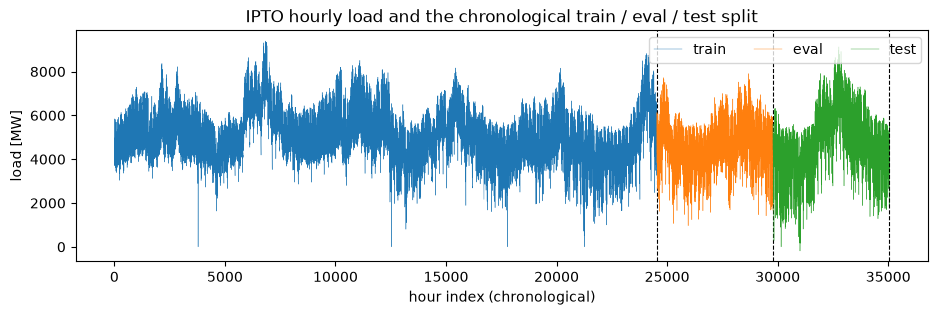

In [4]:
fig, ax = plt.subplots(figsize=(11, 3))
offset = 0
for split, color in (("train", "tab:blue"), ("eval", "tab:orange"), ("test", "tab:green")):
    y = data.denormalize(split, data.targets[split])
    ax.plot(np.arange(offset, offset + y.size), y, lw=0.3, color=color, label=split)
    offset += y.size
    ax.axvline(offset, color="k", lw=0.8, ls="--")
ax.set_xlabel("hour index (chronological)"); ax.set_ylabel("load [MW]"); ax.set_title("IPTO hourly load and the chronological train / eval / test split")
ax.legend(loc="upper right", ncol=3); plt.show()

**What to take from it:** models are tested on the last seven months, after the data they were trained on. The load changes smoothly from hour to hour, so even simple forecasts from the last 4 hours are accurate.

## 2. The paper's numbers reproduce

The paper names Qiskit and NVIDIA CUDA-Q but does not say which simulations run on which, nor with which settings. We therefore wrote a small, fast numpy simulator for these particular circuits (timings: `docs/reproduction_details.md`, *Simulation engine*), and first check that it gives the same values as Qiskit (Figs. 2 and 3).

In [5]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

def qiskit_neuron(x, w):
    # Fig. 2, gate for gate: RX encoding, then 2 blocks of RX(w) and a CX-RZ-CX ladder.
    qc = QuantumCircuit(4)
    for q in range(4): qc.rx(x[q], q)
    for _ in range(2):
        for q in range(4): qc.rx(w[q], q)
        for t in range(1, 4):
            qc.cx(t - 1, t); qc.rz(w[t - 1] - w[t], t); qc.cx(t - 1, t)
    return qc

def qiskit_feature_map(x, n):
    # Fig. 3: 2 blocks of L layers of [H, P(2x)].
    L = int(np.ceil(len(x) / n)); pad = np.zeros(L * n); pad[: len(x)] = x
    qc = QuantumCircuit(n)
    for _ in range(2):
        for layer in range(L):
            for q in range(n): qc.h(q); qc.p(2 * pad[layer * n + q], q)
    return qc

# Compare our code with Qiskit on 20 random draws, without noise.
rng = np.random.default_rng(0)
neuron_err, kernel_err = [], []
for _ in range(20):
    # Quantum neuron: 4 random input values x and 4 fixed random angles w.
    x, w = rng.uniform(-1, 1, 4), rng.uniform(0, 2 * np.pi, 4)
    # Ours: the circuit after the encoding is reduced once to a 16x16 matrix
    # (neuron_functional), then applied to the encoded input (neuron_expectations).
    # The [None] add the neuron and batch axes that the library expects.
    ours = neuron_expectations(neuron_functional(w, IDEAL, "z_all")[None], x[None, None, :])[0, 0]
    # Qiskit: simulate the full circuit and measure <Z Z Z Z>, the observable used here.
    ref = Statevector(qiskit_neuron(x, w)).expectation_value(SparsePauliOp("ZZZZ")).real
    neuron_err.append(abs(ours - ref))

    # Quantum kernel: two inputs of 20 features on 10 qubits, so L = 2 layers per block.
    xa, xb = rng.uniform(-1, 1, (2, 20))
    # Ours: one Bloch vector per qubit for each input, then K = prod_q (1 + b_q(xa) . b_q(xb)) / 2.
    # The last argument 1.0 means no noise (a noisy device shrinks the Bloch vectors).
    ours_k = float(kernel_block(torch.from_numpy(bloch_vectors(xa[None], 10)), torch.from_numpy(bloch_vectors(xb[None], 10)), 1.0)[0, 0])
    # Qiskit: the fidelity |<Phi(xa)|Phi(xb)>|^2 between the two simulated 10-qubit states.
    ref_k = abs(Statevector(qiskit_feature_map(xa, 10)).inner(Statevector(qiskit_feature_map(xb, 10)))) ** 2
    kernel_err.append(abs(ours_k - ref_k))
print(f"quantum neuron, our formula vs Qiskit circuit: largest difference {max(neuron_err):.0e} over 20 random neurons")
print(f"quantum kernel, our formula vs Qiskit circuit: largest difference {max(kernel_err):.0e} over 20 random pairs (10 qubits)")
print("differences of order 1e-16 are rounding errors of 64-bit floats: the values are identical")
assert max(neuron_err) < 1e-10 and max(kernel_err) < 1e-10

quantum neuron, our formula vs Qiskit circuit: largest difference 4e-16 over 20 random neurons
quantum kernel, our formula vs Qiskit circuit: largest difference 6e-17 over 20 random pairs (10 qubits)
differences of order 1e-16 are rounding errors of 64-bit floats: the values are identical


The formulas compute exactly the paper's circuits. Below, every reproduced cell (full data, 3 seeds) next to the paper's value, for the fully quantum model and the paper baseline:

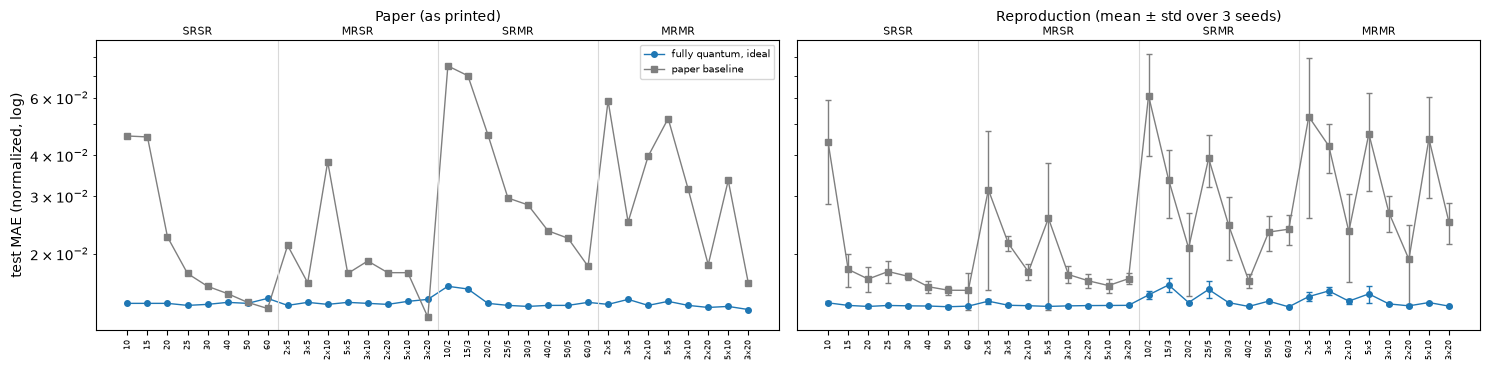

In [6]:
def total_neurons(config):
    # "10" (SRSR), "10/2" (SRMR: neurons / readouts) or "2x5" (MRSR, MRMR: reservoirs x neurons)
    if "x" in config:
        k, n = config.split("x")
        return int(k) * int(n)
    return int(config.split("/")[0])

grid = pd.concat(
    pd.read_csv(RESULTS / f"{arch}_vs_paper.csv", dtype={"configuration": str})
    .assign(order=lambda d: d.configuration.map(total_neurons))
    .sort_values("order", kind="stable")
    for arch in ARCHS
)
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for ax, side in zip(axes, ("Paper (as printed)", "Reproduction (mean ± std over 3 seeds)")):
    for cell, c, m, label in (("quantum_ideal|quantum_kernel_ideal", COLORS["quantum"], "o", "fully quantum, ideal"), ("classical|linear", COLORS["baseline"], "s", "paper baseline")):
        g = grid[(grid.reservoir + "|" + grid.readout) == cell].reset_index(drop=True)
        x = np.arange(len(g))
        if side.startswith("Paper"):
            ax.plot(x, g.mae_paper, color=c, marker=m, ms=4, lw=1, label=label)
        else:
            ax.errorbar(x, g.mae_ours, yerr=g.mae_ours_std, color=c, marker=m, ms=4, lw=1, capsize=2, label=label)
    for i, arch in enumerate(ARCHS):
        if i:
            ax.axvline(8 * i - 0.5, color="0.85", lw=0.8)
        ax.text(8 * i + 3.5, 1.02, arch.upper(), transform=ax.get_xaxis_transform(), ha="center", fontsize=8)
    ax.set_xticks(x, g.configuration, rotation=90, fontsize=6); ax.set_yscale("log"); ax.set_title(side, fontsize=10, pad=14)
axes[0].set_ylabel("test MAE (normalized, log)"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

Our test MAE is close to the paper's (fully quantum cells: median deviation 2.6 %). The table checks the paper's headline, the MAE reduction of its best quantum or hybrid cell relative to the paper baseline:

In [7]:
head = read_json("headline_statistics.json")
rows = []
for arch in ARCHS:
    p, o = head["paper"][arch]["mae"], head["ours"][arch]
    pr, ev = o["paper_rule"]["mae"], o["eval_selected"]["mae"]
    rows.append({"architecture": arch.upper(), "paper, average": p["average"], "ours, average": pr["average_mean"], "± std": pr["average_std"],
                 "ours, eval selection": ev["average_mean"], "paper, peak": p["peak"], "ours, peak": pr["peak_mean"], "peak ± std": pr["peak_std"]})
df = pd.DataFrame(rows)
display(df.style.format({c: "{:.1%}" for c in df.columns if c != "architecture"}).hide(axis="index")
        .set_caption("Test MAE reduction relative to the paper baseline (higher is better)"))

architecture,"paper, average","ours, average",± std,"ours, eval selection","paper, peak","ours, peak",peak ± std
SRSR,28.5%,23.4%,1.5%,22.6%,69.2%,64.9%,12.3%
MRSR,24.7%,26.2%,3.6%,24.5%,63.4%,57.9%,17.4%
SRMR,54.2%,44.1%,3.1%,43.8%,78.8%,75.5%,6.5%
MRMR,52.1%,51.8%,5.9%,51.6%,76.1%,75.4%,7.0%


**Result:** our MAE reductions are of the same order as the paper's (peaks within the seed spread, averages up to 10 points lower for SRMR), and choosing the best cell on the evaluation split barely changes them. The paper's numbers reproduce.

## 3. The gain is not quantum

### 3.1 Against fair classical models, the quantum models are never better

The paper compares its quantum models only with the paper baseline. We add classical models with the same inputs, splits, seeds and evaluation (README, *Fair Baselines*), and pick the best model of each side on the evaluation split. In the figure, compare blue (best quantum) with green (best classical); the grey paper baseline is far above both.

Each architecture is tested at 8 sizes. The tables of Sections 3 and 4 count at how many of them a model is better, tied or worse than another: better means a mean test MAE lower by more than 2 seed standard deviations.

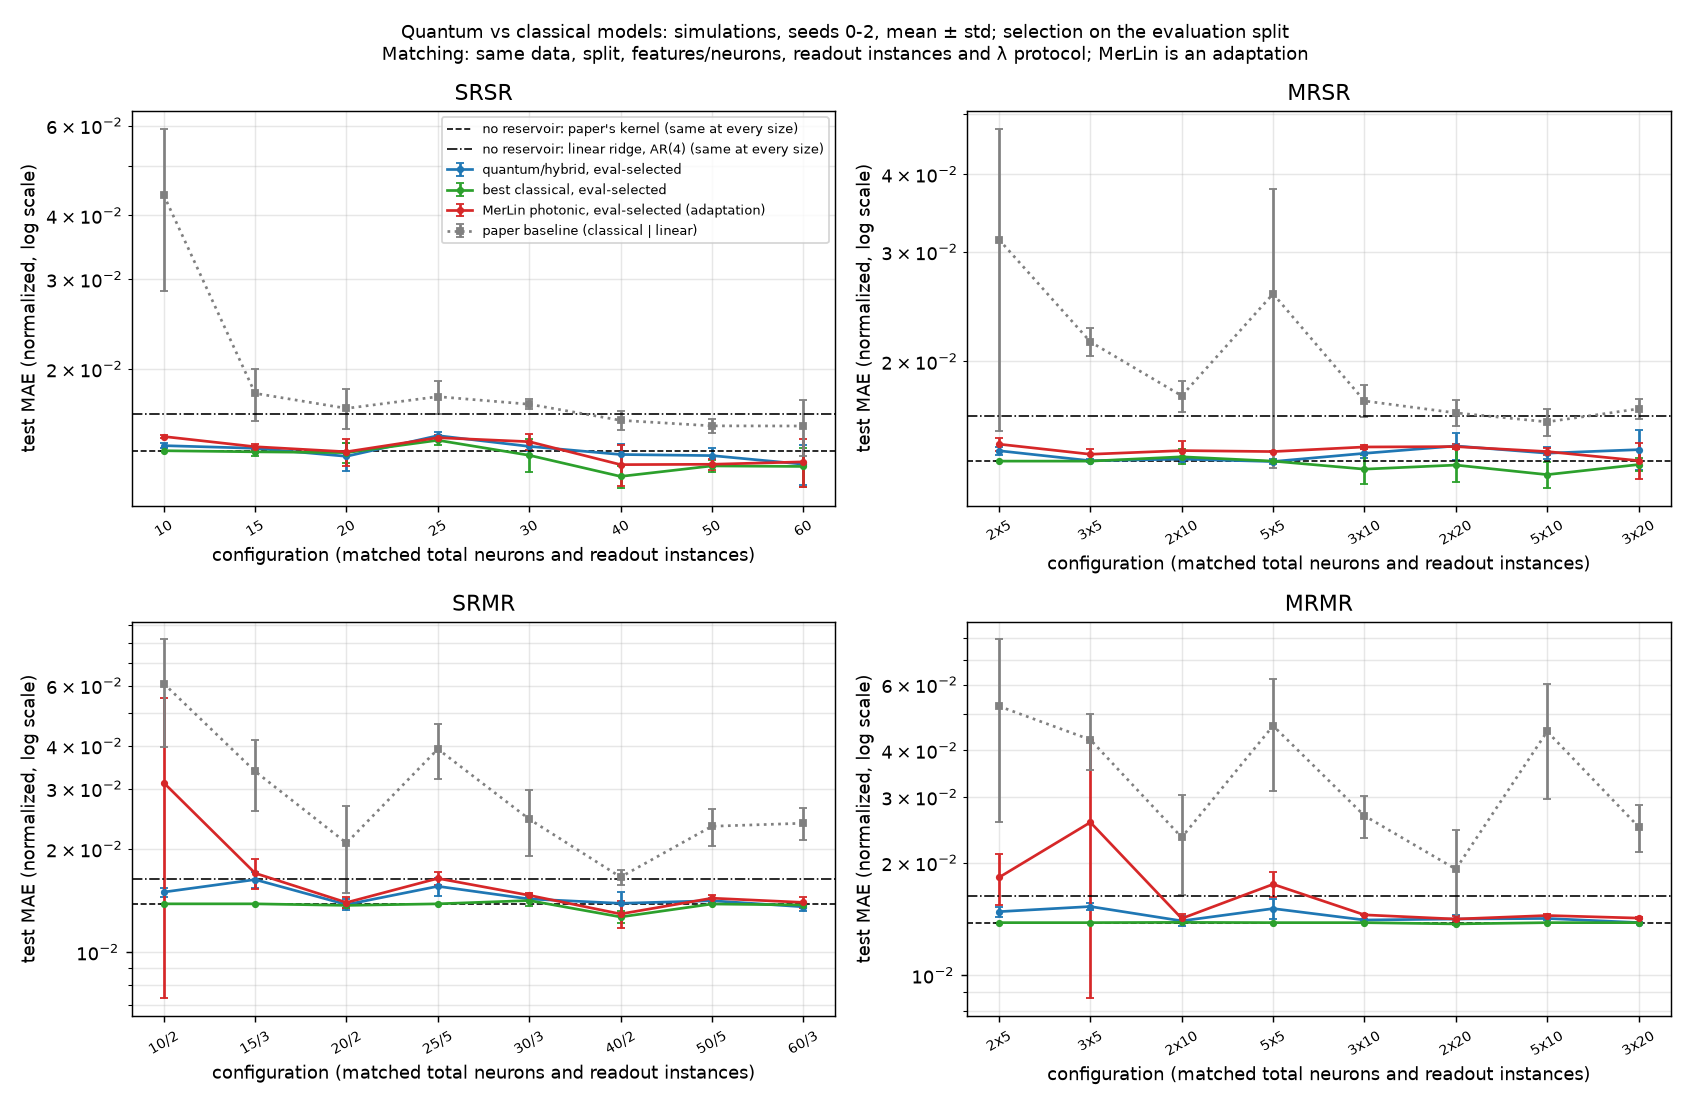

architecture,better / tied / worse,average MAE change
SRSR,0 / 6 / 2,+3.1%
MRSR,0 / 6 / 2,+3.9%
SRMR,0 / 5 / 3,+6.3%
MRMR,0 / 4 / 4,+4.4%


In [8]:
display(Image(filename=str(PAPER_DIR / "results" / "fair_comparison.png"), width=1100))

def verdict(mean_a, std_a, mean_b, std_b):
    # The comparison rule declared before the runs: better if lower by more than 2 pooled seed std.
    gap, pooled = mean_a - mean_b, np.sqrt((std_a**2 + std_b**2) / 2)
    return "better" if gap < -2 * pooled else "worse" if gap > 2 * pooled else "tie"

def counts(verdicts):
    return f"{verdicts.count('better')} / {verdicts.count('tie')} / {verdicts.count('worse')}"

fair = read_json("fair_comparison.json")
rows = []
for arch in ARCHS:
    a = fair["architectures"][arch]
    c = a["claims"]["C1_vs_fair_classical"]["counts"]
    rows.append({"architecture": arch.upper(), "better / tied / worse": f"{c['better']} / {c['tie']} / {c['worse']}",
                 "average MAE change": f"{-a['headline_vs_best_classical']['mae']['average']['mean']:+.1%}"})
display(pd.DataFrame(rows).style.hide(axis="index").set_caption("Best quantum model vs best classical model"))

**Result:** the best quantum model is better at none of the 32 sizes, tied at 21 and worse at 11; on average its MAE is 3–6 % higher than the best classical model's.

### 3.2 The gain comes from the kernel readout, not from the quantum parts

The paper baseline has a linear readout, the best quantum models a kernel readout. To separate the two, we remove the reservoir and apply a kernel directly to the last 4 hours: first the paper's kernel, then a standard classical (RBF) kernel. Neither has neurons, so each is one value at every size (dashed line in the figure above).

In [9]:
rows = []
for arch in ARCHS:
    a = fair["architectures"][arch]
    row = {("", "architecture"): arch.upper()}
    for cell, name in (("raw_lags|quantum_kernel_ideal", "paper's kernel"), ("raw_lags|rbf_kernel", "RBF kernel")):
        v = [verdict(a["per_configuration"][c][cell]["mean"], a["per_configuration"][c][cell]["std"],
                     sel["quantum"]["test_mae"]["mean"], sel["quantum"]["test_mae"]["std"]) for c, sel in a["eval_selected"].items()]
        row[(name, "better / tied / worse")] = counts(v)
    rows.append(row)
df = pd.DataFrame(rows); df.columns = pd.MultiIndex.from_tuples(df.columns)  # two header rows: kernel, then counts
display(df.style.hide(axis="index").set_caption("Kernel without reservoir vs best quantum model"))

,paper's kernel,RBF kernel
architecture,better / tied / worse,better / tied / worse
SRSR,3 / 5 / 0,3 / 5 / 0
MRSR,2 / 6 / 0,2 / 6 / 0
SRMR,4 / 4 / 0,4 / 4 / 0
MRMR,4 / 4 / 0,4 / 4 / 0


**Result:** without any reservoir, the paper's kernel on the last 4 hours is never worse than the best quantum model, and a classical RBF kernel gives the same result. What beats the paper baseline is the kernel readout; neither the quantum reservoir nor the quantum kernel is needed.

## 4. Photonics (MerLin) does about the same as the gate-based model

Each quantum neuron becomes a frozen 2-photon chip, and the kernel a 2-photon chip (README, *Photonic Assessment*; MerLin's outputs are checked against Perceval in `tests/test_photonic.py`). The full photonic grids are run like the gate-based ones, and the best model of each is chosen on the evaluation split. In the figure of Section 3, compare red (MerLin) with blue (best gate-based quantum model).

In [10]:
rows = []
for arch in ARCHS:
    picks = fair["architectures"][arch]["eval_selected"].values()
    v = [verdict(p["merlin"]["test_mae"]["mean"], p["merlin"]["test_mae"]["std"], p["quantum"]["test_mae"]["mean"], p["quantum"]["test_mae"]["std"]) for p in picks]
    change = np.median([p["merlin"]["test_mae"]["mean"] / p["quantum"]["test_mae"]["mean"] - 1 for p in picks])
    rows.append({"architecture": arch.upper(), "better / tied / worse": counts(v), "median MAE change": f"{change:+.1%}"})
display(pd.DataFrame(rows).style.hide(axis="index").set_caption("Best MerLin model vs best gate-based model"))

architecture,better / tied / worse,median MAE change
SRSR,0 / 7 / 1,+0.9%
MRSR,0 / 7 / 1,+2.4%
SRMR,0 / 8 / 0,+2.8%
MRMR,0 / 4 / 4,+3.0%


**Result:** the best MerLin model is tied with the best gate-based model at 26 of 32 sizes and worse at 6, mostly by a few percent at sizes where the seeds agree closely; its median MAE is 1–3 % higher. The architecture carries over to photonics, with the same limit: no gain over the classical models.

## 5. No quantum gain, but an architecture that is easy to distribute

In MRMR, each branch (a reservoir and its own readout) needs only the last 4 hours, and only its forecast leaves it. Distributing the model therefore takes a few lines: run each branch in its own process, here on its own CPU core (later on its own node or QPU), and average the forecasts. To make the speed-up visible, we use a hybrid model larger than the paper's: 5 branches of 60 quantum neurons, each with a linear readout. That a branch-by-branch run equals the reproduction code is tested in `tests/test_distributed.py`.

In [11]:
from concurrent.futures import ProcessPoolExecutor
from functools import partial

from distributed_qrc.lib.architectures import build_cell_spec
from distributed_qrc.lib.distributed import branch_forecast
from distributed_qrc.lib.readouts import merge_predictions

demo_cfg = load_paper_config(); demo_cfg["seed"] = 0
spec = build_cell_spec("mrmr", "5x60")  # 5 branches of 60 quantum neurons (300 in total)
merge = demo_cfg["readout"]["merge"]    # the forecast is the mean of the branch forecasts
# One branch is one self-contained unit of work: input windows in, forecast out.
run_branch = partial(branch_forecast, demo_cfg, data, spec, 0, reservoir_type="quantum_ideal", readout_type="linear")

# 1. Sequential: one process computes the 5 branches one after the other.
t0 = time.perf_counter()
sequential = merge_predictions([run_branch(b)["test"] for b in range(5)], merge)
seconds_one = time.perf_counter() - t0

# 2. Distributed: 5 processes, one per branch, run at the same time on different CPU cores
#    (one thread each, so that the branches do not compete for the same cores).
t0 = time.perf_counter()
with ProcessPoolExecutor(max_workers=5, initializer=torch.set_num_threads, initargs=(1,)) as pool:
    branches = list(pool.map(run_branch, range(5)))
distributed = merge_predictions([b["test"] for b in branches], merge)
seconds_five = time.perf_counter() - t0

runs = pd.DataFrame([
    {"run": "one process, branches in sequence", "seconds": seconds_one, "test MAE": np.abs(data.targets["test"] - sequential).mean()},
    {"run": "five processes, one per branch", "seconds": seconds_five, "test MAE": np.abs(data.targets["test"] - distributed).mean()},
])
display(runs.style.format({"seconds": "{:.1f}", "test MAE": "{:.4f}"}).hide(axis="index").set_caption("MRMR 5x60, quantum reservoirs and linear readouts"))
print(f"speed-up: x{seconds_one / seconds_five:.1f}; largest difference between the two forecasts: {np.abs(distributed - sequential).max():.0e}")

run,seconds,test MAE
"one process, branches in sequence",40.1,0.0146
"five processes, one per branch",14.3,0.0146


speed-up: x2.8; largest difference between the two forecasts: 0e+00


**Result:** the distributed run gives exactly the same forecast, 2.5 to 3 times faster on this laptop (the exact figure varies a little between runs), because each branch simulates its quantum neurons on its own core (the gain includes about 2 s to start the processes). Kernel readouts gain less on a single machine, since their linear algebra already uses all cores in one process; there the gain would come from separate machines. So the paper brings no quantum gain, but an architecture that distributes in a few lines; this cell is the first step of our distributed proof of concept (README, *Next Steps*).

## Conclusion

1. **The paper's numbers reproduce** against the paper baseline (Section 2).
2. **The gain is not quantum:** the best quantum model is never better than the best classical one, and a kernel without reservoir does as well (Section 3).
3. **The architecture holds:** MerLin does about the same as the gate-based model (Section 4), and running the branches in parallel gives the same forecast, faster (Section 5).

Not reproduced: the paper's best model (C5) and its noisy degradation (README, *Verdict per claim*). Limitations: simulation only, 3 seeds per cell, a noise model rebuilt from calibration medians.

In [12]:
print(f"notebook executed in {time.perf_counter() - START:.0f} s on CPU")

notebook executed in 55 s on CPU
